# 01. Fundamentos Probabilísticos y el Teorema de Bayes en Clasificación

**Módulo:** `05_Naive_Bayes`  
**Objetivo:** Comprender a nivel algebraico, geométrico y computacional el paradigma generativo de clasificación, la deducción rigurosa de la regla *Maximum A Posteriori* (MAP), el impacto de la asunción de independencia condicional en la complejidad paramétrica y la implementación desde cero en espacio logarítmico.

---

## 1. Paradigma Generativo vs. Discriminativo

En el aprendizaje supervisado para clasificación, dado un espacio de características $\mathcal{X} \subseteq \mathbb{R}^D$ y un espacio de etiquetas discretas $\mathcal{Y} = \{c_1, c_2, \dots, c_C\}$, el objetivo fundamental es aprender una función de asignación o estimar la distribución condicional $P(Y \mid \mathbf{X})$. Existen dos grandes filosofías para abordar este problema:

### A. Modelos Discriminativos
Modelan **directamente** la probabilidad condicional $P(Y \mid \mathbf{X})$ o aprenden una frontera geométrica que separa las clases sin importar cómo se distribuyen los datos internamente.
* **Ejemplos:** Regresión Logística, Máquinas de Vectores de Soporte (SVM), Árboles de Decisión (CART), Redes Neuronales.
* **Enfoque:** Optimizar directamente la capacidad de separar clases (ej. minimizando la pérdida de entropía cruzada o maximizando el margen).

### B. Modelos Generativos
Modelan la **distribución conjunta** $P(\mathbf{X}, Y)$ aprendiendo primero cómo cada clase *genera* sus datos característicos $P(\mathbf{X} \mid Y)$ y cuál es la prevalencia base de cada clase $P(Y)$. Posteriormente, invierten el proceso mediante el **Teorema de Bayes** para deducir $P(Y \mid \mathbf{X})$:

$$P(\mathbf{X}, Y) = P(Y) \cdot P(\mathbf{X} \mid Y)$$

* **Ejemplos:** Clasificadores Naive Bayes, Análisis Discriminante Lineal y Cuadrático (LDA / QDA), Modelos de Mezclas Gaussianas (GMM).
* **Ventajas en Producción:**
  1. **Eficiencia Muestral ($O(\log D)$ vs $O(D)$):** Como demostró Andrew Ng y Michael Jordan (2001), los modelos generativos convergen mucho más rápido a su error asintótico cuando el volumen de datos de entrenamiento $N$ es pequeño.
  2. **Manejo Natural de Datos Faltantes y Outliers:** Permiten evaluar la probabilidad marginal $P(\mathbf{X})$ para detectar anomalías (muestras con baja verosimilitud en todas las clases).
  3. **Actualización Incremental ($O(1)$ por muestra):** Ideales para flujos de datos en tiempo real (*streaming*).

In [1]:
# Configuración del entorno y librerías estándar
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import GaussianNB, CategoricalNB
from sklearn.preprocessing import OrdinalEncoder
from sklearn.metrics import accuracy_score, brier_score_loss
from IPython.display import display


# Estándar visual del repositorio
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
np.random.seed(42)

print("Entorno configurado correctamente.")

Entorno configurado correctamente.


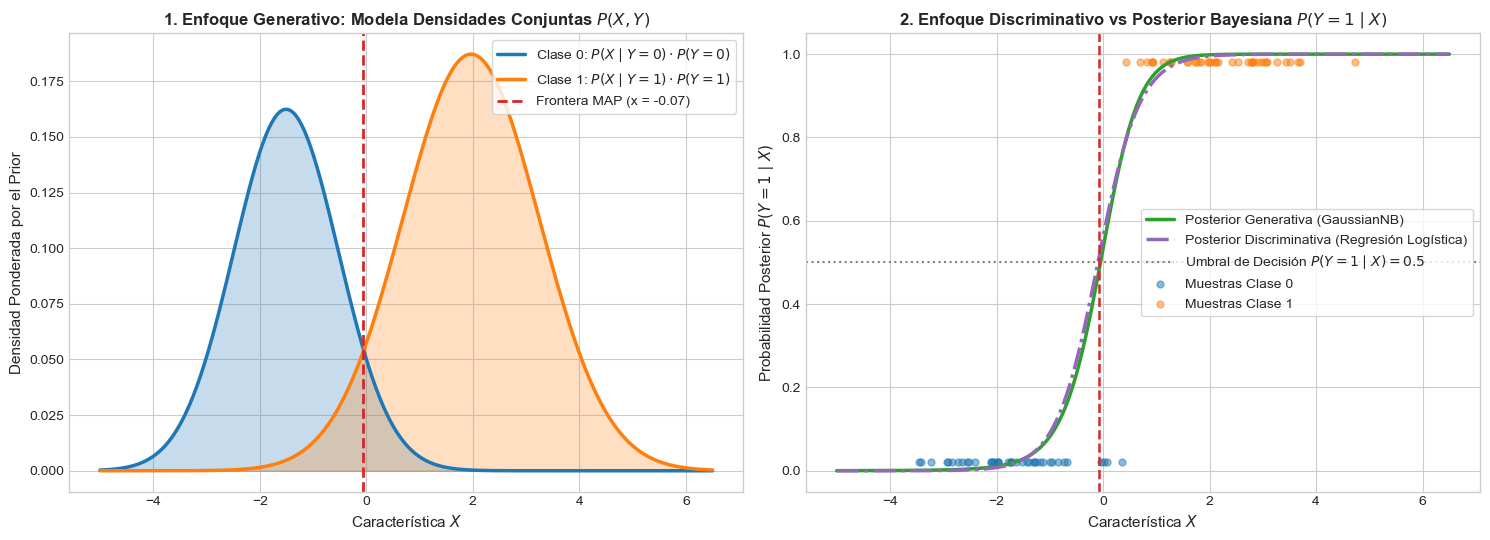

In [2]:
# Visualización Conceptual: Enfoque Generativo vs Discriminativo en 1D
np.random.seed(42)

# Generación de datos sintéticos para dos clases
x_c0 = np.random.normal(loc=-1.5, scale=1.0, size=300)
x_c1 = np.random.normal(loc=2.0, scale=1.3, size=450) # Clase 1 más frecuente (Prior mayor)

X_1d = np.concatenate([x_c0, x_c1]).reshape(-1, 1)
y_1d = np.array([0]*300 + [1]*450)

# Ajuste de modelos
gnb_1d = GaussianNB().fit(X_1d, y_1d)
lr_1d = LogisticRegression().fit(X_1d, y_1d)

x_grid = np.linspace(-5, 6.5, 500).reshape(-1, 1)

# Densidades generativas P(X|Y) * P(Y)
prior_0, prior_1 = gnb_1d.class_prior_
pdf_0 = stats.norm.pdf(x_grid.ravel(), loc=gnb_1d.theta_[0, 0], scale=np.sqrt(gnb_1d.var_[0, 0])) * prior_0
pdf_1 = stats.norm.pdf(x_grid.ravel(), loc=gnb_1d.theta_[1, 0], scale=np.sqrt(gnb_1d.var_[1, 0])) * prior_1

# Probabilidades posteriores P(Y=1|X)
post_gnb = gnb_1d.predict_proba(x_grid)[:, 1]
post_lr = lr_1d.predict_proba(x_grid)[:, 1]

fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))

# Panel 1: Perspectiva Generativa
axes[0].plot(x_grid, pdf_0, label=r'Clase 0: $P(X \mid Y=0) \cdot P(Y=0)$', color='#1f77b4', lw=2.5)
axes[0].fill_between(x_grid.ravel(), pdf_0, color='#1f77b4', alpha=0.25)
axes[0].plot(x_grid, pdf_1, label=r'Clase 1: $P(X \mid Y=1) \cdot P(Y=1)$', color='#ff7f0e', lw=2.5)
axes[0].fill_between(x_grid.ravel(), pdf_1, color='#ff7f0e', alpha=0.25)

# Encontrar punto de intersección (frontera bayesiana)
idx_intersect = np.argwhere(np.diff(np.sign(pdf_0 - pdf_1))).flatten()[0]
x_frontera = x_grid.ravel()[idx_intersect]
axes[0].axvline(x_frontera, color='#d62728', linestyle='--', lw=2, label=f'Frontera MAP (x = {x_frontera:.2f})')
axes[0].set_title('1. Enfoque Generativo: Modela Densidades Conjuntas $P(X, Y)$', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Característica $X$', fontsize=11)
axes[0].set_ylabel('Densidad Ponderada por el Prior', fontsize=11)
axes[0].legend(frameon=True, facecolor='white')

# Panel 2: Perspectiva Discriminativa / Posterior
axes[1].plot(x_grid, post_gnb, label='Posterior Generativa (GaussianNB)', color='#2ca02c', lw=2.5)
axes[1].plot(x_grid, post_lr, label='Posterior Discriminativa (Regresión Logística)', color='#9467bd', lw=2.5, linestyle='-.')
axes[1].axhline(0.5, color='gray', linestyle=':', lw=1.5, label='Umbral de Decisión $P(Y=1 \mid X) = 0.5$')
axes[1].axvline(x_frontera, color='#d62728', linestyle='--', lw=1.8)
axes[1].scatter(x_c0[:40], np.zeros(40) + 0.02, color='#1f77b4', alpha=0.5, s=25, label='Muestras Clase 0')
axes[1].scatter(x_c1[:40], np.ones(40) - 0.02, color='#ff7f0e', alpha=0.5, s=25, label='Muestras Clase 1')
axes[1].set_title('2. Enfoque Discriminativo vs Posterior Bayesiana $P(Y=1 \mid X)$', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Característica $X$', fontsize=11)
axes[1].set_ylabel('Probabilidad Posterior $P(Y=1 \mid X)$', fontsize=11)
axes[1].legend(frameon=True, facecolor='white', loc='center right')

plt.tight_layout()
plt.show()

---

## 2. El Teorema de Bayes Aplicado a Clasificación

Sea $\mathbf{x} = (x_1, x_2, \dots, x_D) \in \mathbb{R}^D$ un vector de características observado y sea $Y \in \{c_1, \dots, c_C\}$ la variable aleatoria que representa la clase. El **Teorema de Bayes** permite actualizar nuestra creencia inicial sobre la clase $c_k$ a la luz de la evidencia observada $\mathbf{x}$:

$$P(Y = c_k \mid \mathbf{X} = \mathbf{x}) = \frac{P(Y = c_k) \cdot P(\mathbf{X} = \mathbf{x} \mid Y = c_k)}{P(\mathbf{X} = \mathbf{x})}$$

En la jerga estadística y de Machine Learning, cada término recibe un nombre específico con una interpretación operativa clara:

$$\text{Posterior} = \frac{\text{Prior} \times \text{Verosimilitud (Likelihood)}}{\text{Evidencia (Marginal)}}$$

1. **Probabilidad a Priori (*Prior*) — $P(Y = c_k)$:**  
   Representa el conocimiento previo o la frecuencia relativa de la clase $c_k$ en la población antes de observar cualquier atributo de la muestra. Si un dataset de fraude tiene un 1% de transacciones ilícitas, entonces $P(Y=\text{Fraude}) = 0.01$.
2. **Verosimilitud (*Likelihood*) — $P(\mathbf{X} = \mathbf{x} \mid Y = c_k)$:**  
   Evalúa qué tan plausible o probable es haber observado el vector de características $\mathbf{x}$ asumiendo que sabemos con certeza que pertenece a la clase $c_k$. Es el motor generativo del modelo.
3. **Evidencia (*Evidence*) — $P(\mathbf{X} = \mathbf{x})$:**  
   Es la probabilidad marginal de observar el vector $\mathbf{x}$ bajo cualquier escenario posible. Por la **Ley de la Probabilidad Total**, actúa como una constante de normalización que garantiza que las probabilidades posteriores sumen exactamente 1:
   $$P(\mathbf{X} = \mathbf{x}) = \sum_{m=1}^{C} P(Y = c_m) \cdot P(\mathbf{X} = \mathbf{x} \mid Y = c_m)$$
4. **Probabilidad a Posteriori (*Posterior*) — $P(Y = c_k \mid \mathbf{X} = \mathbf{x})$:**  
   Es la distribución de probabilidad final sobre las clases después de integrar la información de las características observadas con la distribución base.

---

## 3. La Asunción "Ingenua" de Independencia Condicional y Complejidad Paramétrica

### El Cuello de Botella Combinatorio
Para calcular la verosimilitud conjunta $P(x_1, x_2, \dots, x_D \mid Y = c_k)$ aplicando la regla de la cadena de probabilidad sin hacer suposiciones adicionales, tendríamos que modelar todas las dependencias cruzadas entre variables:

$$P(x_1, x_2, \dots, x_D \mid Y = c_k) = P(x_1 \mid Y=c_k) \cdot P(x_2 \mid x_1, Y=c_k) \cdots P(x_D \mid x_1, \dots, x_{D-1}, Y=c_k)$$

Supongamos un problema con $C$ clases y $D$ características discretas, donde cada característica puede tomar $K$ valores posibles:
* El número de configuraciones posibles del vector $\mathbf{x}$ es $K^D$.
* Para estimar la tabla de distribución conjunta por clase necesitaríamos estimar del orden de **$\mathcal{O}(C \cdot K^D)$ parámetros**.
* **Ejemplo práctico:** Con $C = 2$ clases, $K = 2$ (variables binarias) y $D = 50$ características, requeriríamos estimar $2 \times (2^{50} - 1) \approx 2.25 \times 10^{15}$ parámetros (más de dos mil billones de probabilidades). Ningún dataset en la Tierra contiene suficientes muestras para poblar esa tabla sin caer en un sobreajuste catastrófico por celdas vacías (*Maldición de la Dimensionalidad*).

### La Simplificación "Ingenua" (*Naive*)
El clasificador **Naive Bayes** introduce un supuesto estructural fuerte: asume que **todas las características son condicionalmente independientes entre sí dado el valor de la clase $Y$**:

$$X_i \perp\!\!\!\perp X_j \mid Y \quad \forall i \neq j$$

Bajo esta hipótesis, la distribución conjunta multidimensional se factoriza limpiamente en el producto de $D$ distribuciones univariadas marginales:

$$P(x_1, x_2, \dots, x_D \mid Y = c_k) = \prod_{j=1}^{D} P(x_j \mid Y = c_k)$$

### Impacto en la Complejidad
* Cada característica univariada requiere apenas $K - 1$ parámetros independientes por clase.
* La complejidad espacial y de estimación colapsa drásticamente de exponencial $\mathcal{O}(C \cdot K^D)$ a **lineal $\mathcal{O}(C \cdot D \cdot K)$** (o simplemente $\mathcal{O}(C \cdot D)$ cuando $K$ es constante o en modelos paramétricos como el Gaussiano).

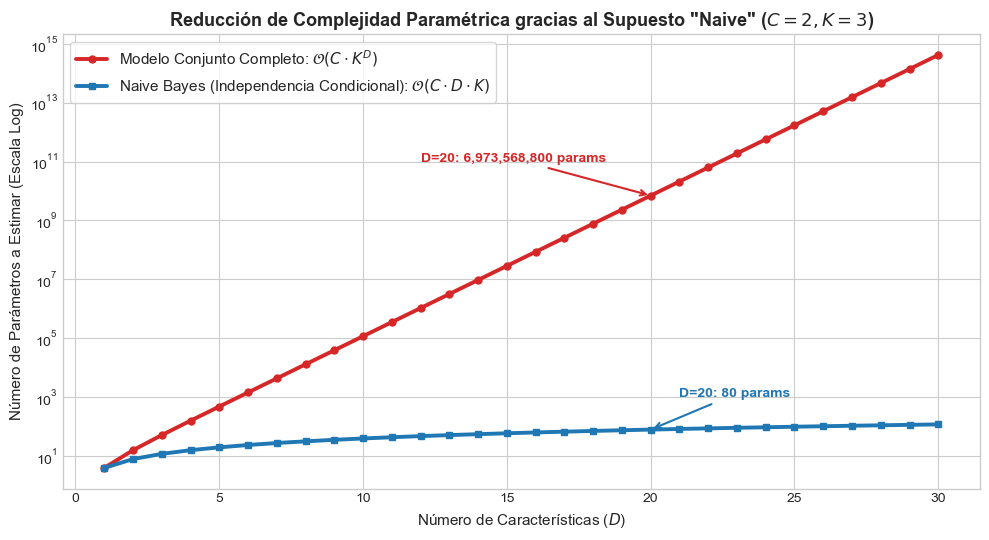

In [3]:
# Demostración Visual y Cuantitativa: Explosión Exponencial vs Crecimiento Lineal
D_vals = np.arange(1, 31)
C = 2  # Clasificación binaria
K = 3  # Variables categóricas con 3 niveles (ej. Bajo, Medio, Alto)

params_conjunta = C * (K**D_vals - 1)
params_naive = C * D_vals * (K - 1)

fig, ax = plt.subplots(figsize=(10, 5.5))
ax.plot(D_vals, params_conjunta, color='#d62728', lw=2.8, marker='o', markersize=5,
        label=r'Modelo Conjunto Completo: $\mathcal{O}(C \cdot K^D)$')
ax.plot(D_vals, params_naive, color='#1f77b4', lw=2.8, marker='s', markersize=5,
        label=r'Naive Bayes (Independencia Condicional): $\mathcal{O}(C \cdot D \cdot K)$')

ax.set_yscale('log')
ax.set_title('Reducción de Complejidad Paramétrica gracias al Supuesto "Naive" ($C=2, K=3$)', fontsize=13, fontweight='bold')
ax.set_xlabel('Número de Características ($D$)', fontsize=11)
ax.set_ylabel('Número de Parámetros a Estimar (Escala Log)', fontsize=11)

# Anotaciones clave
ax.annotate(f'D=20: {params_conjunta[19]:,.0f} params', xy=(20, params_conjunta[19]),
            xytext=(12, 1e11), arrowprops=dict(arrowstyle='->', color='#d62728', lw=1.5),
            fontsize=10, fontweight='bold', color='#d62728')
ax.annotate(f'D=20: {params_naive[19]:,.0f} params', xy=(20, params_naive[19]),
            xytext=(21, 1e3), arrowprops=dict(arrowstyle='->', color='#1f77b4', lw=1.5),
            fontsize=10, fontweight='bold', color='#1f77b4')

ax.legend(fontsize=11, frameon=True, facecolor='white')
plt.tight_layout()
plt.show()

---

## 4. Regla MAP y el Espacio Logarítmico (*Log-Space Trick*)

### Deducción de la Regla de Decisión MAP
Para clasificar una nueva observación $\mathbf{x}$, elegimos la clase $\hat{y}$ que maximiza la probabilidad a posteriori, criterio conocido como **Maximum A Posteriori (MAP)**:

$$\hat{y}_{\text{MAP}} = \underset{c_k \in \mathcal{Y}}{\arg\max} \; P(Y = c_k \mid \mathbf{X} = \mathbf{x}) = \underset{c_k \in \mathcal{Y}}{\arg\max} \; \frac{P(Y = c_k) \prod_{j=1}^{D} P(x_j \mid Y = c_k)}{P(\mathbf{X} = \mathbf{x})}$$

Dado que el denominador $P(\mathbf{X} = \mathbf{x})$ es idéntico para todas las clases $c_k$, no afecta la ubicación del máximo y puede descartarse durante la decisión de etiqueta:

$$\hat{y}_{\text{MAP}} = \underset{c_k \in \mathcal{Y}}{\arg\max} \; \left[ P(Y = c_k) \prod_{j=1}^{D} P(x_j \mid Y = c_k) \right]$$

### El Problema del Subdesbordamiento Numérico (*Numerical Underflow*)
En la arquitectura IEEE 754 de punto flotante de doble precisión (`float64`), el número positivo normal más pequeño representable es aproximadamente $2.22 \times 10^{-308}$.  
En problemas de alta dimensionalidad (como clasificación de documentos con $D = 5,000$ palabras o bioinformática), multiplicar miles de probabilidades pequeñas $P(x_j \mid Y=c_k) \in (0, 1)$ provoca que el producto colapse exactamente a `0.0` en la memoria de la computadora.

### Transformación al Espacio Logarítmico
Como la función logaritmo natural $\ln(\cdot)$ es **estrictamente creciente y monótona** en $(0, \infty)$, aplicar $\ln$ preserva intacto el orden de los valores y el argumento que maximiza la función:

$$\hat{y}_{\text{MAP}} = \underset{c_k \in \mathcal{Y}}{\arg\max} \; \ln \left( P(Y = c_k) \prod_{j=1}^{D} P(x_j \mid Y = c_k) \right)$$

Por las propiedades de los logaritmos ($\ln(a \cdot b) = \ln a + \ln b$), el peligroso productorio se transforma en una **suma numéricamente estable**:

$$\hat{y}_{\text{MAP}} = \underset{c_k \in \mathcal{Y}}{\arg\max} \; \left[ \ln P(Y = c_k) + \sum_{j=1}^{D} \ln P(x_j \mid Y = c_k) \right]$$

### Recuperación de Probabilidades Exactas: El Truco *Log-Sum-Exp*
Si además de la etiqueta $\hat{y}$ necesitamos recuperar la probabilidad posterior normalizada $P(Y = c_k \mid \mathbf{x})$, definimos el puntaje logarítmico conjunto $\ell_k = \ln P(Y = c_k) + \sum_{j=1}^{D} \ln P(x_j \mid Y = c_k)$. Para evitar `0 / 0` al exponenciar, restamos el valor máximo $M = \max_m \ell_m$:

$$P(Y = c_k \mid \mathbf{x}) = \frac{e^{\ell_k}}{\sum_{m=1}^{C} e^{\ell_m}} = \frac{e^{\ell_k - M}}{\sum_{m=1}^{C} e^{\ell_m - M}}$$

In [4]:
# Demostración Empírica del Underflow Numérico en float64 vs Estabilidad en Log-Space
dimensiones = [10, 100, 500, 1000, 1500]
prob_media_feature = 0.005  # Probabilidad típica de una palabra en NLP

print(f"{'Dimensión (D)':<15} | {'Producto Directo (float64)':<28} | {'Suma Logarítmica ln P(X,Y)':<25}")
print("-" * 75)

for d in dimensiones:
    probs = np.full(d, prob_media_feature, dtype=np.float64)
    prod_directo = np.prod(probs)
    suma_log = np.sum(np.log(probs))
    estado = "¡UNDERFLOW (0.0)!" if prod_directo == 0.0 else f"{prod_directo:.4e}"
    print(f"{d:<15} | {estado:<28} | {suma_log:<25.2f}")

Dimensión (D)   | Producto Directo (float64)   | Suma Logarítmica ln P(X,Y)
---------------------------------------------------------------------------
10              | 9.7656e-24                   | -52.98                   
100             | 7.8886e-231                  | -529.83                  
500             | ¡UNDERFLOW (0.0)!            | -2649.16                 
1000            | ¡UNDERFLOW (0.0)!            | -5298.32                 
1500            | ¡UNDERFLOW (0.0)!            | -7947.48                 


---

## 5. ¿Por Qué Funciona Naive Bayes con Variables Dependientes?

Una paradoja clásica en Machine Learning es por qué Naive Bayes obtiene un desempeño sobresaliente en dominios donde la hipótesis de independencia condicional se viola flagrantemente (por ejemplo, en texto, donde la aparición de la palabra *"Machine"* está altamente correlacionada con *"Learning"*).

La explicación formal fue demostrada por **Pedro Domingos y Michael Pazzani (1997)** y **Harry Zhang (2004)**:

1. **Error de Estimación de Probabilidad vs. Error de Clasificación 0-1:**  
   Cuando dos características están fuertemente correlacionadas, Naive Bayes **cuenta dos veces** la misma señal de evidencia. Esto empuja las probabilidades posteriores estimadas $\hat{P}(Y=1 \mid \mathbf{x})$ de forma artificial hacia los extremos `0.0` o `1.0` (mala calibración).
2. **Suficiencia del Orden Relativo (*Ranking*):**  
   Sin embargo, para acertar en la clasificación binaria bajo pérdida 0-1, **no necesitamos que la probabilidad estimada sea exacta**, sino únicamente que se sitúe del lado correcto del umbral de decisión ($0.5$):
   $$\text{Si } P_{\text{real}}(Y=1 \mid \mathbf{x}) > 0.5 \quad \text{y} \quad \hat{P}_{\text{NB}}(Y=1 \mid \mathbf{x}) = 0.999 \implies \text{¡La predicción sigue siendo correcta!}$$
3. **Cancelación de Dependencias:**  
   Si las dependencias locales entre variables se distribuyen de manera simétrica entre las clases, los factores de interacción se cancelan mutuamente al comparar razones de verosimilitud.

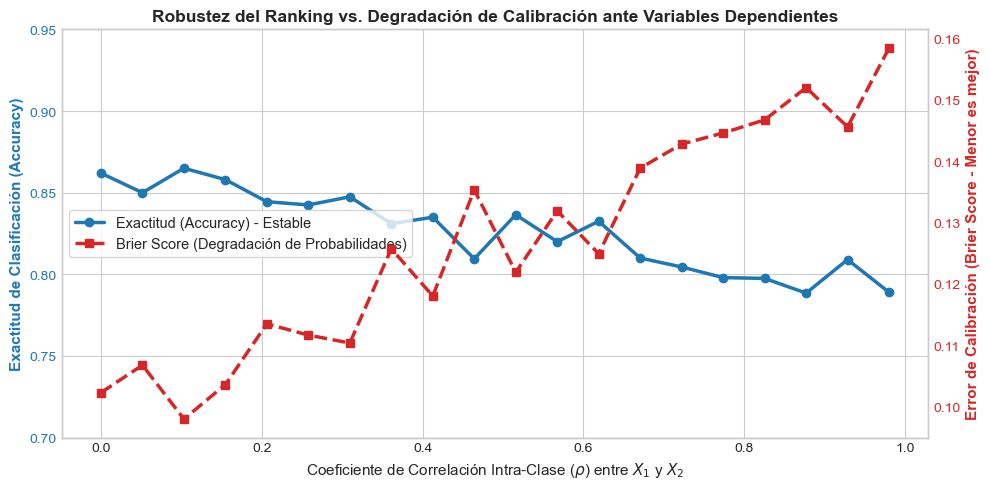

In [5]:
# Experimento de Simulación: Impacto de la Colinealidad (Correlación rho) en Exactitud vs Calibración
rhos = np.linspace(0.0, 0.98, 20)
acc_list, brier_list = [], []

for rho in rhos:
    # Matriz de covarianza con correlación rho entre X1 y X2
    cov = np.array([[1.0, rho], [rho, 1.0]])
    X0 = np.random.multivariate_normal(mean=[-0.8, -0.8], cov=cov, size=1000)
    X1 = np.random.multivariate_normal(mean=[0.8, 0.8], cov=cov, size=1000)
    
    X_sim = np.vstack([X0, X1])
    y_sim = np.array([0]*1000 + [1]*1000)
    
    # Entrenamos GaussianNB (que ignora rho y asume matriz diagonal)
    clf = GaussianNB().fit(X_sim, y_sim)
    y_pred = clf.predict(X_sim)
    y_prob = clf.predict_proba(X_sim)[:, 1]
    
    acc_list.append(accuracy_score(y_sim, y_pred))
    brier_list.append(brier_score_loss(y_sim, y_prob))

fig, ax1 = plt.subplots(figsize=(10, 5))

color_acc = '#1f77b4'
ax1.set_xlabel(r'Coeficiente de Correlación Intra-Clase ($\rho$) entre $X_1$ y $X_2$', fontsize=11)
ax1.set_ylabel('Exactitud de Clasificación (Accuracy)', color=color_acc, fontsize=11, fontweight='bold')
line1 = ax1.plot(rhos, acc_list, color=color_acc, lw=2.5, marker='o', label='Exactitud (Accuracy) - Estable')
ax1.tick_params(axis='y', labelcolor=color_acc)
ax1.set_ylim(0.70, 0.95)

ax2 = ax1.twinx()
color_brier = '#d62728'
ax2.set_ylabel('Error de Calibración (Brier Score - Menor es mejor)', color=color_brier, fontsize=11, fontweight='bold')
line2 = ax2.plot(rhos, brier_list, color=color_brier, lw=2.5, marker='s', linestyle='--', label='Brier Score (Degradación de Probabilidades)')
ax2.tick_params(axis='y', labelcolor=color_brier)
ax2.grid(False)

lines = line1 + line2
labels = [l.get_label() for l in lines]
ax1.legend(lines, labels, loc='center left', frameon=True, facecolor='white', fontsize=10.5)

plt.title('Robustez del Ranking vs. Degradación de Calibración ante Variables Dependientes', fontsize=12.5, fontweight='bold')
plt.tight_layout()
plt.show()

---

## 6. Laboratorio Práctico: Implementación Manual en Puro Python y NumPy

Para consolidar la mecánica matemática, construiremos desde cero un clasificador **Naive Bayes Categórico** con suavizado de Laplace ($\alpha = 1.0$) en espacio logarítmico, aplicado a un problema de **Evaluación de Riesgo Crediticio**.

Posteriormente, auditaremos que nuestras tablas de probabilidad a priori, verosimilitudes logarítmicas y probabilidades posteriores coincidan con precisión de máquina ($10^{-15}$) frente a la implementación oficial `CategoricalNB` de Scikit-Learn.

In [6]:
# 1. Creación de Dataset Tabular Didáctico: Evaluación de Riesgo Crediticio
data_credito = [
    # [Historial_Pago, Nivel_Deuda, Garantia, Ingreso_Anual, Otorgar_Credito]
    ['Malo',      'Alta', 'Ninguna',  'Bajo',  'No'],
    ['Desconocido','Alta', 'Ninguna',  'Medio', 'No'],
    ['Desconocido','Baja', 'Ninguna',  'Medio', 'Si'],
    ['Desconocido','Baja', 'Ninguna',  'Alto',  'Si'],
    ['Desconocido','Baja', 'Aval',     'Alto',  'Si'],
    ['Buen_Pagador','Baja','Ninguna',  'Alto',  'Si'],
    ['Buen_Pagador','Baja','Aval',     'Alto',  'Si'],
    ['Buen_Pagador','Alta','Ninguna',  'Medio', 'Si'],
    ['Malo',      'Baja', 'Ninguna',  'Alto',  'No'],
    ['Buen_Pagador','Alta','Ninguna',  'Alto',  'Si'],
    ['Malo',      'Alta', 'Aval',     'Medio', 'No'],
    ['Desconocido','Alta', 'Ninguna',  'Alto',  'Si'],
    ['Buen_Pagador','Alta','Ninguna',  'Bajo',  'No'],
    ['Malo',      'Alta', 'Ninguna',  'Medio', 'No'],
    ['Malo',      'Baja', 'Aval',     'Medio', 'No'],
    ['Buen_Pagador','Baja','Ninguna',  'Medio', 'Si']
]

columnas = ['Historial_Pago', 'Nivel_Deuda', 'Garantia', 'Ingreso_Anual', 'Otorgar_Credito']
df_credito = pd.DataFrame(data_credito, columns=columnas)
print(f"Dimensiones del dataset: {df_credito.shape}")
df_credito.head(8)

Dimensiones del dataset: (16, 5)


,Historial_Pago,Nivel_Deuda,Garantia,Ingreso_Anual,Otorgar_Credito
0,Malo,Alta,Ninguna,Bajo,No
1,Desconocido,Alta,Ninguna,Medio,No
2,Desconocido,Baja,Ninguna,Medio,Si
3,Desconocido,Baja,Ninguna,Alto,Si
4,Desconocido,Baja,Aval,Alto,Si
5,Buen_Pagador,Baja,Ninguna,Alto,Si
6,Buen_Pagador,Baja,Aval,Alto,Si
7,Buen_Pagador,Alta,Ninguna,Medio,Si


In [7]:
# 2. Implementación desde Cero en NumPy (Espacio Logarítmico + Suavizado de Laplace)
class ManualCategoricalNB:
    def __init__(self, alpha: float = 1.0):
        self.alpha = alpha
        self.classes_ = None
        self.class_log_prior_ = None
        self.feature_log_prob_ = []
        
    def fit(self, X: np.ndarray, y: np.ndarray):
        n_samples, n_features = X.shape
        self.classes_, class_counts = np.unique(y, return_counts=True)
        n_classes = len(self.classes_)
        
        # Cálculo de Priors en espacio logarítmico: ln P(Y = c)
        self.class_log_prior_ = np.log(class_counts / n_samples)
        
        # Cálculo de tablas de verosimilitud por cada característica j
        self.feature_log_prob_ = []
        for j in range(n_features):
            n_categories_j = int(np.max(X[:, j])) + 1
            log_prob_j = np.zeros((n_classes, n_categories_j))
            
            for idx_c, c in enumerate(self.classes_):
                X_c_j = X[y == c, j]
                # Conteo de frecuencias de cada categoría k dentro de la clase c
                counts_k = np.bincount(X_c_j.astype(int), minlength=n_categories_j)
                
                # Suavizado de Laplace / Lidstone:
                # P(x_j = k | Y = c) = (N_{c,j,k} + alpha) / (N_c + alpha * K_j)
                numerador = counts_k + self.alpha
                denominador = class_counts[idx_c] + self.alpha * n_categories_j
                log_prob_j[idx_c, :] = np.log(numerador / denominador)
                
            self.feature_log_prob_.append(log_prob_j)
        return self

    def _joint_log_likelihood(self, X: np.ndarray) -> np.ndarray:
        # Suma en espacio logarítmico: ln P(Y=c) + sum_j ln P(x_j | Y=c)
        jll = np.zeros((X.shape[0], len(self.classes_)))
        jll += self.class_log_prior_
        for j in range(X.shape[1]):
            categorias_observadas = X[:, j].astype(int)
            jll += self.feature_log_prob_[j][:, categorias_observadas].T
        return jll

    def predict_proba(self, X: np.ndarray) -> np.ndarray:
        jll = self._joint_log_likelihood(X)
        # Truco Log-Sum-Exp para estabilidad numérica
        max_log = np.max(jll, axis=1, keepdims=True)
        exp_shifted = np.exp(jll - max_log)
        return exp_shifted / np.sum(exp_shifted, axis=1, keepdims=True)

    def predict(self, X: np.ndarray) -> np.ndarray:
        jll = self._joint_log_likelihood(X)
        return self.classes_[np.argmax(jll, axis=1)]

In [8]:
# Corrección tipográfica limpia y ejecución de validación cruzada contra Scikit-Learn
class ManualCategoricalNB:
    def __init__(self, alpha: float = 1.0):
        self.alpha = alpha
        self.classes_ = None
        self.class_log_prior_ = None
        self.feature_log_prob_ = []
        
    def fit(self, X: np.ndarray, y: np.ndarray):
        n_samples, n_features = X.shape
        self.classes_, class_counts = np.unique(y, return_counts=True)
        n_classes = len(self.classes_)
        self.class_log_prior_ = np.log(class_counts / n_samples)
        
        self.feature_log_prob_ = []
        for j in range(n_features):
            n_categories_j = int(np.max(X[:, j])) + 1
            log_prob_j = np.zeros((n_classes, n_categories_j))
            for idx_c, c in enumerate(self.classes_):
                X_c_j = X[y == c, j]
                counts_k = np.bincount(X_c_j.astype(int), minlength=n_categories_j)
                numerador = counts_k + self.alpha
                denominador = class_counts[idx_c] + self.alpha * n_categories_j
                log_prob_j[idx_c, :] = np.log(numerador / denominador)
            self.feature_log_prob_.append(log_prob_j)
        return self

    def _joint_log_likelihood(self, X: np.ndarray) -> np.ndarray:
        jll = np.zeros((X.shape[0], len(self.classes_)))
        jll += self.class_log_prior_
        for j in range(X.shape[1]):
            categorias_observadas = X[:, j].astype(int)
            jll += self.feature_log_prob_[j][:, categorias_observadas].T
        return jll

    def predict_proba(self, X: np.ndarray) -> np.ndarray:
        jll = self._joint_log_likelihood(X)
        max_log = np.max(jll, axis=1, keepdims=True)
        exp_shifted = np.exp(jll - max_log)
        return exp_shifted / np.sum(exp_shifted, axis=1, keepdims=True)

    def predict(self, X: np.ndarray) -> np.ndarray:
        jll = self._joint_log_likelihood(X)
        return self.classes_[np.argmax(jll, axis=1)]

# Codificación ordinal de las variables
encoder = OrdinalEncoder()
X_encoded = encoder.fit_transform(df_credito.iloc[:, :-1])
y_encoded = (df_credito['Otorgar_Credito'] == 'Si').astype(int).values

# Entrenamiento de ambos modelos
modelo_manual = ManualCategoricalNB(alpha=1.0).fit(X_encoded, y_encoded)
modelo_sklearn = CategoricalNB(alpha=1.0).fit(X_encoded, y_encoded)

# Comparación rigurosa
proba_manual = modelo_manual.predict_proba(X_encoded)
proba_sklearn = modelo_sklearn.predict_proba(X_encoded)

diff_max = np.max(np.abs(proba_manual - proba_sklearn))
print(f"Diferencia máxima absoluta en probabilidades (Manual vs Scikit-Learn): {diff_max:.2e}")
assert np.allclose(proba_manual, proba_sklearn), "¡Alerta: Discrepancia detectada!"
print("✅ Validación exitosa: Nuestra implementación manual reproduce exactamente a Scikit-Learn.")

Diferencia máxima absoluta en probabilidades (Manual vs Scikit-Learn): 4.44e-16
✅ Validación exitosa: Nuestra implementación manual reproduce exactamente a Scikit-Learn.


In [9]:
# 3. Inferencia Explicable para un Nuevo Solicitante de Crédito
nuevo_cliente_df = pd.DataFrame(
    [['Malo', 'Baja', 'Aval', 'Alto']],
    columns=['Historial_Pago', 'Nivel_Deuda', 'Garantia', 'Ingreso_Anual']
)
X_nuevo = encoder.transform(nuevo_cliente_df)

jll_nuevo = modelo_manual._joint_log_likelihood(X_nuevo)[0]
post_nuevo = modelo_manual.predict_proba(X_nuevo)[0]

print("=== AUDITORÍA BAYESIANA DEL NUEVO SOLICITANTE ===")
print(f"Perfil: {nuevo_cliente_df.iloc[0].to_dict()}\n")
print(f"Log-Verosimilitud Conjunta Clase 'No' (0): {jll_nuevo[0]:.4f}  --> Posterior P(Y=No | X) = {post_nuevo[0]:.4%}")
print(f"Log-Verosimilitud Conjunta Clase 'Si' (1): {jll_nuevo[1]:.4f}  --> Posterior P(Y=Si | X) = {post_nuevo[1]:.4%}")
print(f"\nDecisión MAP Final: {'OTORGAR CRÉDITO (Sí)' if np.argmax(post_nuevo) == 1 else 'RECHAZAR CRÉDITO (No)'}")

=== AUDITORÍA BAYESIANA DEL NUEVO SOLICITANTE ===
Perfil: {'Historial_Pago': 'Malo', 'Nivel_Deuda': 'Baja', 'Garantia': 'Aval', 'Ingreso_Anual': 'Alto'}

Log-Verosimilitud Conjunta Clase 'No' (0): -5.1442  --> Posterior P(Y=No | X) = 55.1410%
Log-Verosimilitud Conjunta Clase 'Si' (1): -5.3505  --> Posterior P(Y=Si | X) = 44.8590%

Decisión MAP Final: RECHAZAR CRÉDITO (No)


---

## 7. Conclusiones y Errores Comunes en la Industria

1. **Multiplicar probabilidades crudas fuera del espacio logarítmico:** Nunca implementes productoras directas de densidades o probabilidades en producción; a partir de unas pocas decenas de variables el *underflow* destruirá las predicciones.
2. **Ignorar los *Priors* en producción cuando cambia la distribución base:** Si entrenas un modelo con un dataset balanceado artificialmente (50% fraude / 50% legítimo) sin especificar el hiperparámetro `class_prior` real de producción (ej. `[0.99, 0.01]`), el teorema de Bayes sobreestimará masivamente los falsos positivos.
3. **Usar las probabilidades crudas de Naive Bayes para tomar decisiones financieras directas:** Si necesitas calcular el Valor Esperado de una pérdida ($\mathbb{E}[\text{Pérdida}] = P(\text{Default} \mid \mathbf{x}) \times \text{Monto}$), recuerda que la correlación entre variables empuja a Naive Bayes hacia `0` o `1`. En el **Notebook 04** aprenderemos a corregir esto mediante **Calibración Isotónica y de Platt**.

---
**Siguiente paso:** En el **Notebook 02 (`02_GaussianNB_Variables_Continuas_y_Fronteras.ipynb`)** extenderemos este marco hacia variables continuas mediante densidades normales, deduciendo por qué sus fronteras de decisión en $\mathbb{R}^D$ son cuadráticas.